<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


# Biểu đồ tròn (Pie Charts), Box Plot, Biểu đồ phân tán (Scatter Plots) và Biểu đồ bong bóng (Bubble Plots)


Thời gian ước tính cần thiết: **30** phút
    

## Mục tiêu

Sau khi hoàn thành bài thực hành này, bạn sẽ có thể:

* Khám phá sâu hơn thư viện Matplotlib
* Tạo biểu đồ tròn (pie charts), box plot, biểu đồ phân tán (scatter plots) và biểu đồ bong bóng (bubble charts)

## Mục lục

<div class="alert alert-block alert-info" style="margin-top: 20px">

1. [Khám phá bộ dữ liệu với *p*andas](#0)<br>
2. [Tải xuống và chuẩn bị dữ liệu](#2)<br>
3. [Trực quan hóa dữ liệu bằng Matplotlib](#4) <br>
4. [Biểu đồ tròn (Pie Charts)](#6) <br>
5. [Box Plot](#8) <br>
6. [Biểu đồ phân tán (Scatter Plots)](#10) <br>
7. [Biểu đồ bong bóng (Bubble Plots)](#12) <br> 
</div>


# Khám phá bộ dữ liệu với *pandas* và Matplotlib<a id="0"></a>

Bộ công cụ: Khóa học phụ thuộc nhiều vào [*pandas*](http://pandas.pydata.org/) và [**Numpy**](http://www.numpy.org/) để xử lý (data wrangling), phân tích và trực quan hóa dữ liệu. Thư viện vẽ biểu đồ chính mà chúng ta sẽ tìm hiểu trong khóa học là [Matplotlib](http://matplotlib.org/).

Bộ dữ liệu: Nhập cư vào Canada từ năm 1980 đến 2013 - [International migration flows to and from selected countries - The 2015 revision](http://www.un.org/en/development/desa/population/migration/data/empirical2/migrationflows.shtml) từ trang web của Liên Hợp Quốc.

Bộ dữ liệu chứa dữ liệu hằng năm về các luồng người di cư quốc tế do các quốc gia đến ghi nhận. Dữ liệu thể hiện cả luồng nhập và luồng xuất theo nơi sinh, quốc tịch hoặc nơi cư trú trước đó / tiếp theo, đối với cả người nước ngoài và công dân. Trong bài thực hành này, chúng ta sẽ tập trung vào dữ liệu nhập cư vào Canada.

# Tải xuống và chuẩn bị dữ liệu <a id="2"></a>

Việc đầu tiên chúng ta làm là cài đặt **openpyxl** (trước đây là **xlrd**), một module mà *pandas* cần để đọc các tệp Excel.

In [1]:
!pip3 install openpyxl==3.1.0

Import các module chính.

In [2]:
import numpy as np  # useful for many scientific computing in Python
import pandas as pd # primary data structure library

Tải xuống bộ dữ liệu nhập cư Canada và đọc nó vào một dataframe của *pandas*.

In [25]:
df_can = pd.read_excel(
    'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/Canada.xlsx',
    sheet_name='Canada by Citizenship',
    skiprows=range(20),
    skipfooter=2
    )

print('Data downloaded and read into a dataframe!')

Data downloaded and read into a dataframe!


Hãy xem qua năm phần tử đầu tiên trong bộ dữ liệu của chúng ta.

In [26]:
df_can.head()

,Type,Coverage,OdName,AREA,AreaName,REG,RegName,DEV,DevName,1980,...,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013
0,Immigrants,Foreigners,Afghanistan,935,Asia,5501,Southern Asia,902,Developing regions,16,...,2978,3436,3009,2652,2111,1746,1758,2203,2635,2004
1,Immigrants,Foreigners,Albania,908,Europe,925,Southern Europe,901,Developed regions,1,...,1450,1223,856,702,560,716,561,539,620,603
2,Immigrants,Foreigners,Algeria,903,Africa,912,Northern Africa,902,Developing regions,80,...,3616,3626,4807,3623,4005,5393,4752,4325,3774,4331
3,Immigrants,Foreigners,American Samoa,909,Oceania,957,Polynesia,902,Developing regions,0,...,0,0,1,0,0,0,0,0,0,0
4,Immigrants,Foreigners,Andorra,908,Europe,925,Southern Europe,901,Developed regions,0,...,0,0,1,1,0,0,0,0,1,1


Hãy tìm xem có bao nhiêu mục (entry) trong bộ dữ liệu của chúng ta.

In [27]:
# print the dimensions of the dataframe
print(df_can.shape)

(195, 43)


Làm sạch dữ liệu. Chúng ta sẽ thực hiện một số thay đổi đối với bộ dữ liệu gốc để việc tạo các hình ảnh trực quan dễ dàng hơn. Hãy tham khảo *Introduction to Matplotlib and Line Plots* và *Area Plots, Histograms, and Bar Plots* để biết mô tả chi tiết về bước tiền xử lý này.

In [28]:
# clean up the dataset to remove unnecessary columns (eg. REG) 
df_can.drop(['AREA', 'REG', 'DEV', 'Type', 'Coverage'], axis=1, inplace=True)

# let's rename the columns so that they make sense
df_can.rename(columns={'OdName':'Country', 'AreaName':'Continent','RegName':'Region'}, inplace=True)

# for sake of consistency, let's also make all column labels of type string
df_can.columns = list(map(str, df_can.columns))

# set the country name as index - useful for quickly looking up countries using .loc method
df_can.set_index('Country', inplace=True)

# add total column
df_can['Total'] = df_can.loc[:,"1980":"2013"].sum(axis=1)

# years that we will be using in this lesson - useful for plotting later on
years = list(map(str, range(1980, 2014)))
print('data dimensions:', df_can.shape)

data dimensions: (195, 38)


# Trực quan hóa dữ liệu bằng Matplotlib<a id="4"></a>

Import `Matplotlib`.

In [29]:
%matplotlib inline

import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.style.use('ggplot') # optional: for ggplot-like style

# check for latest version of Matplotlib
print('Matplotlib version: ', mpl.__version__) # >= 2.0.0

Matplotlib version:  3.10.0


# Biểu đồ tròn (Pie Charts) <a id="6"></a>

`Pie chart` là một dạng đồ họa hình tròn hiển thị các tỷ lệ số bằng cách chia một hình tròn (hay chiếc bánh) thành các phần (slice) tương ứng với tỷ lệ. Bạn rất có thể đã quen thuộc với biểu đồ tròn vì nó được sử dụng rộng rãi trong kinh doanh và truyền thông. Chúng ta có thể tạo biểu đồ tròn trong Matplotlib bằng cách truyền từ khóa `kind=pie`.

Hãy dùng biểu đồ tròn để khám phá tỷ lệ (phần trăm) người nhập cư mới được nhóm theo châu lục trong toàn bộ giai đoạn từ 1980 đến 2013. 

Bước 1: Thu thập dữ liệu. 

Chúng ta sẽ dùng phương thức `groupby` của *pandas* để tổng hợp dữ liệu nhập cư theo `Continent`. Quy trình chung của `groupby` gồm các bước sau:

1. **Split (Tách):** Tách dữ liệu thành các nhóm dựa trên một tiêu chí nào đó.
2. **Apply (Áp dụng):** Áp dụng một hàm cho từng nhóm một cách độc lập:
       .sum()
       .count()
       .mean() 
       .std() 
       .aggregate()
       .apply()
       .etc..
3. **Combine (Kết hợp):** Kết hợp các kết quả thành một cấu trúc dữ liệu.

<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/Module%203/images/Mod3Fig4SplitApplyCombine.png" height="400" align="center">

In [30]:
# group countries by continents and apply sum() function 
df_continents = df_can.groupby('Continent', axis=0).sum()

# note: the output of the groupby method is a `groupby' object. 
# we can not use it further until we apply a function (eg .sum())
print(type(df_can.groupby('Continent', axis=0)))

df_continents.head()

<class 'pandas.core.groupby.generic.DataFrameGroupBy'>


/tmp/ipykernel_1885/1749182422.py:2: FutureWarning: The 'axis' keyword in DataFrame.groupby is deprecated and will be removed in a future version.
  df_continents = df_can.groupby('Continent', axis=0).sum()
/tmp/ipykernel_1885/1749182422.py:6: FutureWarning: The 'axis' keyword in DataFrame.groupby is deprecated and will be removed in a future version.
  print(type(df_can.groupby('Continent', axis=0)))


,Region,DevName,1980,1981,1982,1983,1984,1985,1986,1987,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
Continent,,,,,,,,,,,,,,,,,,,,,
Africa,Northern AfricaMiddle AfricaWestern AfricaSout...,Developing regionsDeveloping regionsDeveloping...,3951,4363,3819,2671,2639,2650,3782,7494,...,27523,29188,28284,29890,34534,40892,35441,38083,38543,618948
Asia,Southern AsiaWestern AsiaWestern AsiaWestern A...,Developing regionsDeveloping regionsDeveloping...,31025,34314,30214,24696,27274,23850,28739,43203,...,159253,149054,133459,139894,141434,163845,146894,152218,155075,3317794
Europe,Southern EuropeSouthern EuropeWestern EuropeEa...,Developed regionsDeveloped regionsDeveloped re...,39760,44802,42720,24638,22287,20844,24370,46698,...,35955,33053,33495,34692,35078,33425,26778,29177,28691,1410947
Latin America and the Caribbean,CaribbeanSouth AmericaCaribbeanCaribbeanCentra...,Developing regionsDeveloping regionsDeveloping...,13081,15215,16769,15427,13678,15171,21179,28471,...,24747,24676,26011,26547,26867,28818,27856,27173,24950,765148
Northern America,Northern AmericaNorthern America,Developed regionsDeveloped regions,9378,10030,9074,7100,6661,6543,7074,7705,...,8394,9613,9463,10190,8995,8142,7677,7892,8503,241142


Bước 2: Vẽ biểu đồ dữ liệu. Chúng ta sẽ truyền từ khóa `kind = 'pie'`, cùng với các tham số bổ sung sau:
- `autopct` -  là một chuỗi hoặc hàm dùng để gán nhãn cho các phần (wedge) bằng giá trị số của chúng. Nhãn sẽ được đặt bên trong phần đó. Nếu là một chuỗi định dạng (format string), nhãn sẽ là `fmt%pct`.
- `startangle` - xoay điểm bắt đầu của biểu đồ tròn một góc (tính bằng độ) ngược chiều kim đồng hồ so với trục x.
- `shadow` - Vẽ bóng bên dưới biểu đồ tròn (để tạo cảm giác 3D).

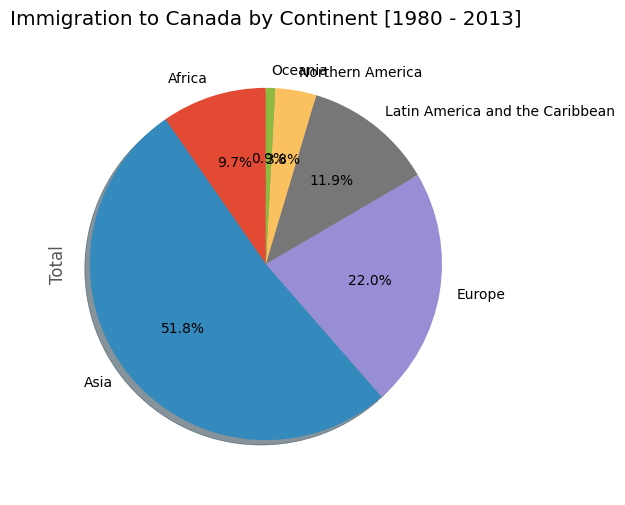

In [31]:
# autopct create %, start angle represent starting point
df_continents['Total'].plot(kind='pie',
                            figsize=(5, 6),
                            autopct='%1.1f%%', # add in percentages
                            startangle=90,     # start angle 90° (Africa)
                            shadow=True,       # add shadow      
                            )

plt.title('Immigration to Canada by Continent [1980 - 2013]')
plt.axis('equal') # Sets the pie chart to look like a circle.

plt.show()

Hình ảnh ở trên chưa rõ ràng lắm, các con số và văn bản chồng lên nhau ở một số chỗ. Hãy thực hiện một vài chỉnh sửa để cải thiện hình ảnh:

* Loại bỏ các nhãn văn bản trên biểu đồ tròn bằng cách truyền `legend` và thêm nó dưới dạng một chú giải (legend) riêng bằng `plt.legend()`.
* Đẩy các giá trị phần trăm ra ngay bên ngoài biểu đồ tròn bằng cách truyền tham số `pctdistance`.
* Truyền một bộ màu tùy chỉnh cho các châu lục bằng tham số `colors`.
* **Explode** (tách) biểu đồ tròn để nhấn mạnh ba châu lục thấp nhất (Africa, North America và Latin America and Caribbean) bằng cách truyền tham số `explode`.

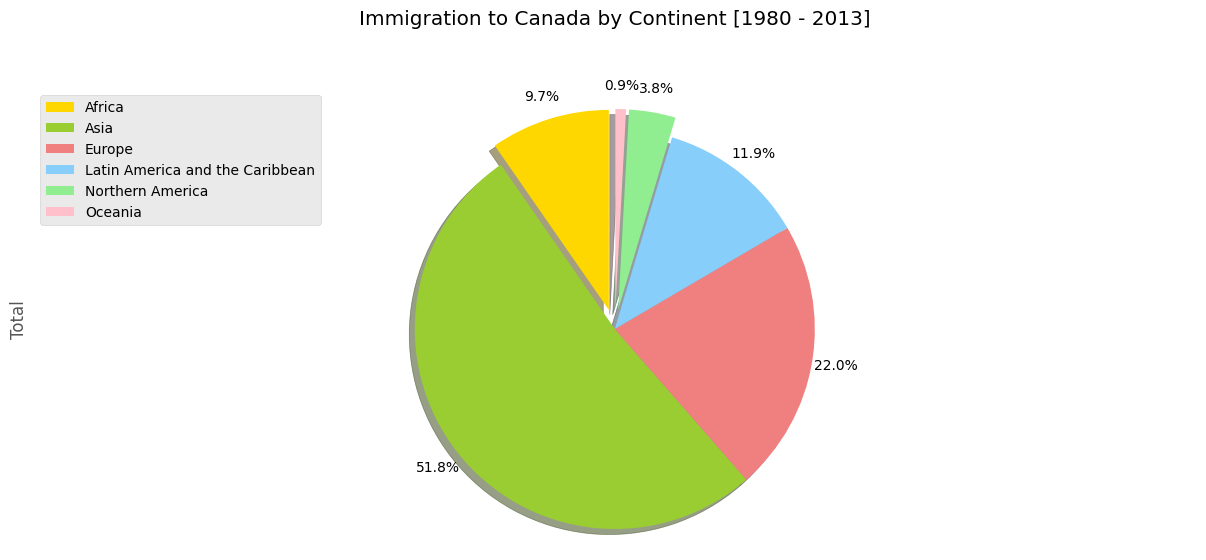

In [32]:
colors_list = ['gold', 'yellowgreen', 'lightcoral', 'lightskyblue', 'lightgreen', 'pink']
explode_list = [0.1, 0, 0, 0, 0.1, 0.1] # ratio for each continent with which to offset each wedge.

df_continents['Total'].plot(kind='pie',
                            figsize=(15, 6),
                            autopct='%1.1f%%', 
                            startangle=90,    
                            shadow=True,       
                            labels=None,         # turn off labels on pie chart
                            pctdistance=1.12,    # the ratio between the center of each pie slice and the start of the text generated by autopct 
                            colors=colors_list,  # add custom colors
                            explode=explode_list # 'explode' lowest 3 continents
                            )

# scale the title up by 12% to match pctdistance
plt.title('Immigration to Canada by Continent [1980 - 2013]', y=1.12) 

plt.axis('equal') 

# add legend
plt.legend(labels=df_continents.index, loc='upper left') 

plt.show()

**Câu hỏi:** Sử dụng biểu đồ tròn, hãy khám phá tỷ lệ (phần trăm) người nhập cư mới được nhóm theo châu lục trong năm 2013.

**Lưu ý**: Bạn có thể cần điều chỉnh các giá trị explode để khắc phục tình trạng các giá trị của các phần bị chồng lên nhau.

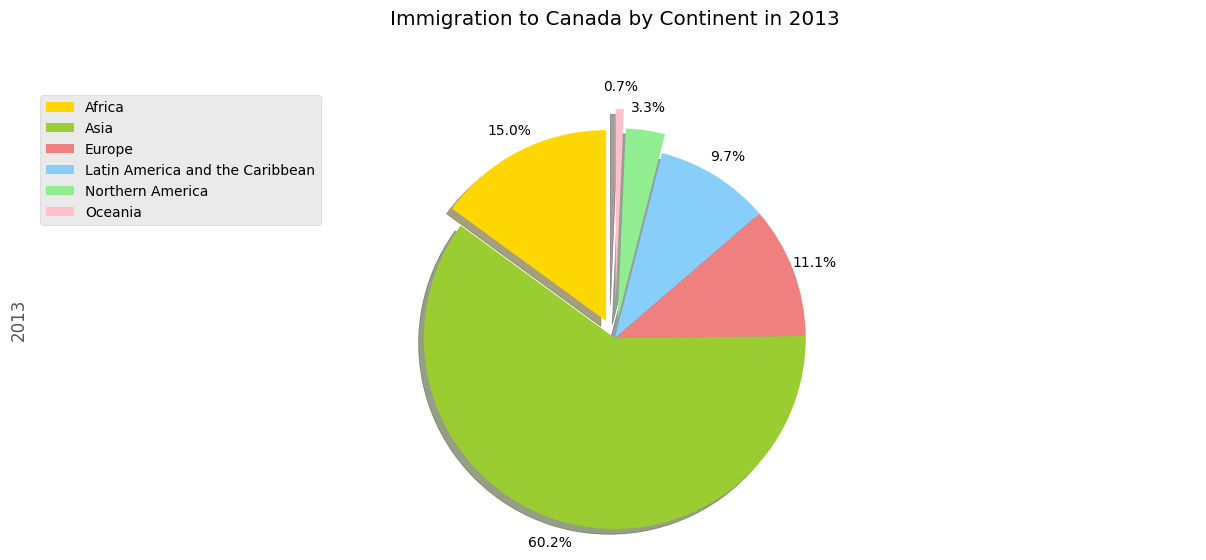

In [37]:
### type your answer here
df_2013 = df_continents['2013']

colors_list = ['gold', 'yellowgreen', 'lightcoral', 'lightskyblue', 'lightgreen', 'pink']
explode_list = [0.1, 0, 0, 0, 0.1, 0.2] # ratio for each continent with which to offset each wedge.

df_2013.plot(kind='pie',
                            figsize=(15, 6),
                            autopct='%1.1f%%', 
                            startangle=90,    
                            shadow=True,       
                            labels=None,         # turn off labels on pie chart
                            pctdistance=1.12,    # the ratio between the center of each pie slice and the start of the text generated by autopct 
                            colors=colors_list,  # add custom colors
                            explode=explode_list # 'explode' lowest 3 continents
                            )

# scale the title up by 12% to match pctdistance
plt.title('Immigration to Canada by Continent in 2013', y=1.12) 

plt.axis('equal') 

# add legend
plt.legend(labels=df_continents.index, loc='upper left') 

plt.show()

<details><summary>Nhấn vào đây để xem gợi ý về các hàm cần dùng</summary>

### 💡 Gợi ý

Bạn có thể cân nhắc các hàm sau:

- <code style="color:red">plot()</code> — `kind='pie'` cùng `autopct`, `startangle`, `shadow`, `labels`, `pctdistance`, `explode`.
- <code style="color:red">plt.title()</code> — có thể dùng tham số `y` để nâng tiêu đề lên nếu bị chồng chữ.
- <code style="color:red">plt.axis()</code> — giữ tỷ lệ hai trục bằng nhau để biểu đồ tròn không bị méo.
- <code style="color:red">plt.legend()</code> — thêm chú giải bằng tên các châu lục (index của `df_continents`).
- <code style="color:red">plt.show()</code> — hiển thị biểu đồ.

> **Mẹo:** Thử thay đổi các giá trị trong danh sách `explode` để tránh các phần bị chồng nhau.

</details>

# Box Plot <a id="8"></a>

`Box plot` là một cách biểu diễn *phân phối* của dữ liệu theo thống kê thông qua năm thông số chính: 

- **Minimum (Giá trị nhỏ nhất):** Số nhỏ nhất trong bộ dữ liệu, không tính các outlier.
- **First quartile (Tứ phân vị thứ nhất):** Số ở giữa `minimum` và `median`.
- **Second quartile (Tứ phân vị thứ hai - Median):** Số ở giữa của bộ dữ liệu (đã sắp xếp).
- **Third quartile (Tứ phân vị thứ ba):** Số ở giữa `median` và `maximum`.
- **Maximum (Giá trị lớn nhất):** Số lớn nhất trong bộ dữ liệu, không tính các outlier.

<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/Module%203/images/boxplot_complete.png" width="440," align="center">

Để tạo `boxplot`, chúng ta có thể dùng `kind=box` trong phương thức `plot` được gọi trên một series hoặc dataframe của *pandas*.

Hãy vẽ box plot cho người nhập cư Nhật Bản (Japan) trong giai đoạn 1980 - 2013.

Bước 1: Lấy tập con của bộ dữ liệu. Mặc dù chúng ta chỉ trích xuất dữ liệu của một quốc gia, chúng ta vẫn sẽ lấy nó dưới dạng dataframe. Điều này sẽ giúp chúng ta gọi phương thức `dataframe.describe()` để xem các phân vị (percentile).

In [38]:
# to get a dataframe, place extra square brackets around 'Japan'.
df_japan = df_can.loc[['Japan'], years].transpose()
df_japan.head()

Country,Japan
1980,701
1981,756
1982,598
1983,309
1984,246


Bước 2: Vẽ biểu đồ bằng cách truyền `kind='box'`.

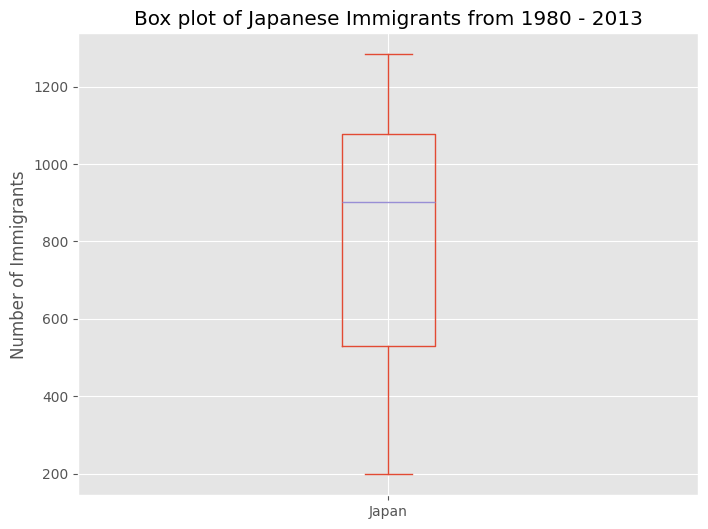

In [39]:
df_japan.plot(kind='box', figsize=(8, 6))

plt.title('Box plot of Japanese Immigrants from 1980 - 2013')
plt.ylabel('Number of Immigrants')

plt.show()

Chúng ta có thể ngay lập tức đưa ra một vài nhận xét quan trọng từ biểu đồ ở trên:
1. Số người nhập cư nhỏ nhất vào khoảng 200 (min), số lớn nhất vào khoảng 1300 (max), và số người nhập cư trung vị (median) vào khoảng 900.
2. 25% số năm trong giai đoạn 1980 - 2013 có số người nhập cư hằng năm là ~500 hoặc thấp hơn (Tứ phân vị thứ nhất).
2. 75% số năm trong giai đoạn 1980 - 2013 có số người nhập cư hằng năm là ~1100 hoặc thấp hơn (Tứ phân vị thứ ba).

Chúng ta có thể xem các con số thực tế bằng cách gọi phương thức `describe()` trên dataframe.

In [40]:
df_japan.describe()

Country,Japan
count,34.000000
mean,814.911765
std,337.219771
min,198.000000
25%,529.000000
50%,902.000000
75%,1079.000000
max,1284.000000


Một trong những lợi ích chính của box plot là so sánh phân phối của nhiều bộ dữ liệu. Trong một bài thực hành trước, chúng ta đã quan sát thấy Trung Quốc và Ấn Độ có xu hướng nhập cư rất giống nhau. Hãy phân tích sâu hơn hai quốc gia này bằng box plot.

**Câu hỏi:** So sánh phân phối số lượng người nhập cư mới từ Ấn Độ và Trung Quốc trong giai đoạn 1980 - 2013.

Bước 1: Lấy bộ dữ liệu của Trung Quốc và Ấn Độ và đặt tên dataframe là **df_CI**.

In [42]:
### type your answer here
df_CI = df_can.loc[['China', 'India'], years].transpose()

<details><summary>Nhấn vào đây để xem gợi ý về các hàm cần dùng</summary>

### 💡 Gợi ý

Bạn có thể cân nhắc các hàm sau:

- <code style="color:red">loc[]</code> — chọn hai quốc gia theo tên cùng các cột năm.
- <code style="color:red">transpose()</code> — để mỗi quốc gia là một cột.
- <code style="color:red">head()</code> — xem nhanh kết quả.

</details>

Hãy xem các phân vị liên quan đến cả hai quốc gia bằng phương thức `describe()`.

In [43]:
### type your answer here
df_CI.describe()


Country,China,India
count,34.000000,34.000000
mean,19410.647059,20350.117647
std,13568.230790,10007.342579
min,1527.000000,4211.000000
25%,5512.750000,10637.750000
50%,19945.000000,20235.000000
75%,31568.500000,28699.500000
max,42584.000000,36210.000000


<details><summary>Nhấn vào đây để xem gợi ý về các hàm cần dùng</summary>

### 💡 Gợi ý

Bạn có thể cân nhắc các hàm sau:

- <code style="color:red">describe()</code> — gọi trên dataframe `df_CI`.

</details>

Bước 2: Vẽ dữ liệu.

Text(0, 0.5, 'Number of Immigrants')

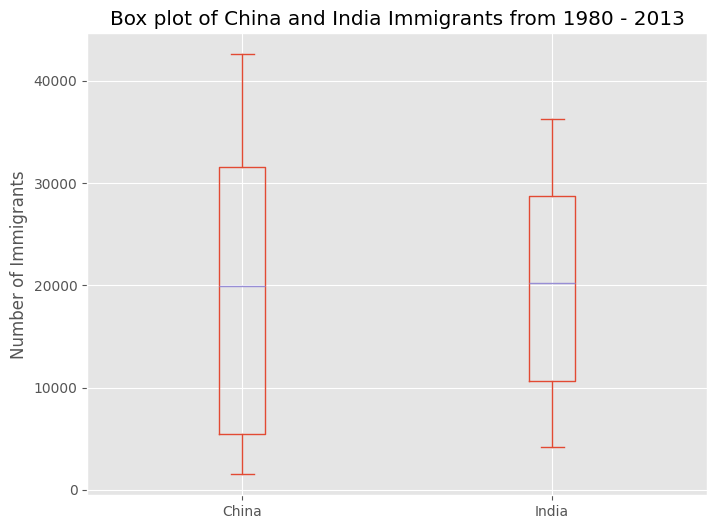

In [45]:
### type your answer here

df_CI.plot(kind='box', figsize=(8, 6))

plt.title('Box plot of China and India Immigrants from 1980 - 2013')
plt.ylabel('Number of Immigrants')


<details><summary>Nhấn vào đây để xem gợi ý về các hàm cần dùng</summary>

### 💡 Gợi ý

Bạn có thể cân nhắc các hàm sau:

- <code style="color:red">plot()</code> — `kind='box'` cùng `figsize`.
- <code style="color:red">plt.title()</code> — tiêu đề.
- <code style="color:red">plt.ylabel()</code> — nhãn trục y.
- <code style="color:red">plt.show()</code> — hiển thị biểu đồ.

</details>

Chúng ta có thể quan sát thấy rằng, trong khi cả hai quốc gia có dân số nhập cư trung vị xấp xỉ nhau (~20,000), phạm vi dân số nhập cư của Trung Quốc phân tán rộng hơn so với Ấn Độ. Dân số tối đa từ Ấn Độ trong bất kỳ năm nào (36,210) thấp hơn khoảng 15% so với dân số tối đa từ Trung Quốc (42,584).

Nếu bạn muốn tạo box plot nằm ngang, bạn có thể truyền tham số `vert` vào hàm **plot** và gán giá trị *False*. Bạn cũng có thể chỉ định một màu khác nếu không thích màu đỏ mặc định.

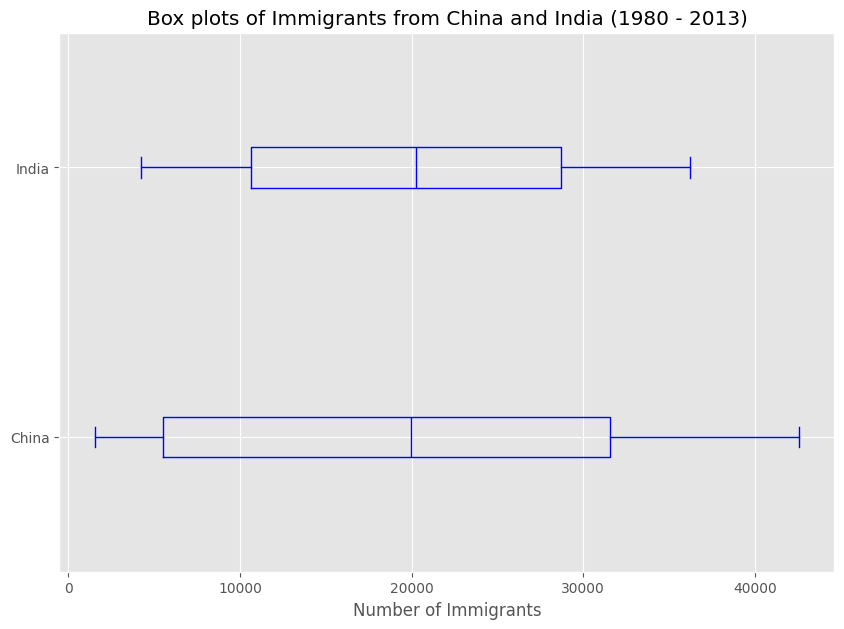

In [46]:
# horizontal box plots
df_CI.plot(kind='box', figsize=(10, 7), color='blue', vert=False)

plt.title('Box plots of Immigrants from China and India (1980 - 2013)')
plt.xlabel('Number of Immigrants')

plt.show()

**Subplot**

Nhiều khi chúng ta muốn vẽ nhiều biểu đồ trong cùng một figure. Ví dụ, chúng ta có thể muốn so sánh song song box plot với biểu đồ đường (line plot) về lượng nhập cư của Trung Quốc và Ấn Độ.

Để trực quan hóa nhiều biểu đồ cùng nhau, chúng ta có thể tạo một **`figure`** (khung vẽ tổng thể) và chia nó thành các **`subplots`**, mỗi subplot chứa một biểu đồ. Với **subplots**, chúng ta thường làm việc với **artist layer** thay vì **scripting layer**. 

Cú pháp thông thường là: <br>
```python
    fig = plt.figure() # create figure
    ax = fig.add_subplot(nrows, ncols, plot_number) # create subplots
```
Trong đó
- `nrows` và `ncols` được dùng để chia figure về mặt khái niệm thành (`nrows` \* `ncols`) sub-axes,  
- `plot_number` được dùng để xác định subplot cụ thể mà hàm này sẽ tạo trong lưới khái niệm. `plot_number` bắt đầu từ 1, tăng dần theo từng dòng trước và có giá trị tối đa là `nrows` * `ncols` như hình bên dưới.

<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/Module%203/images/Mod3Fig5Subplots_V2.png" width="500" align="center">

Sau đó chúng ta có thể chỉ định subplot để đặt từng biểu đồ bằng cách truyền tham số `ax` vào phương thức `plot()` như sau:

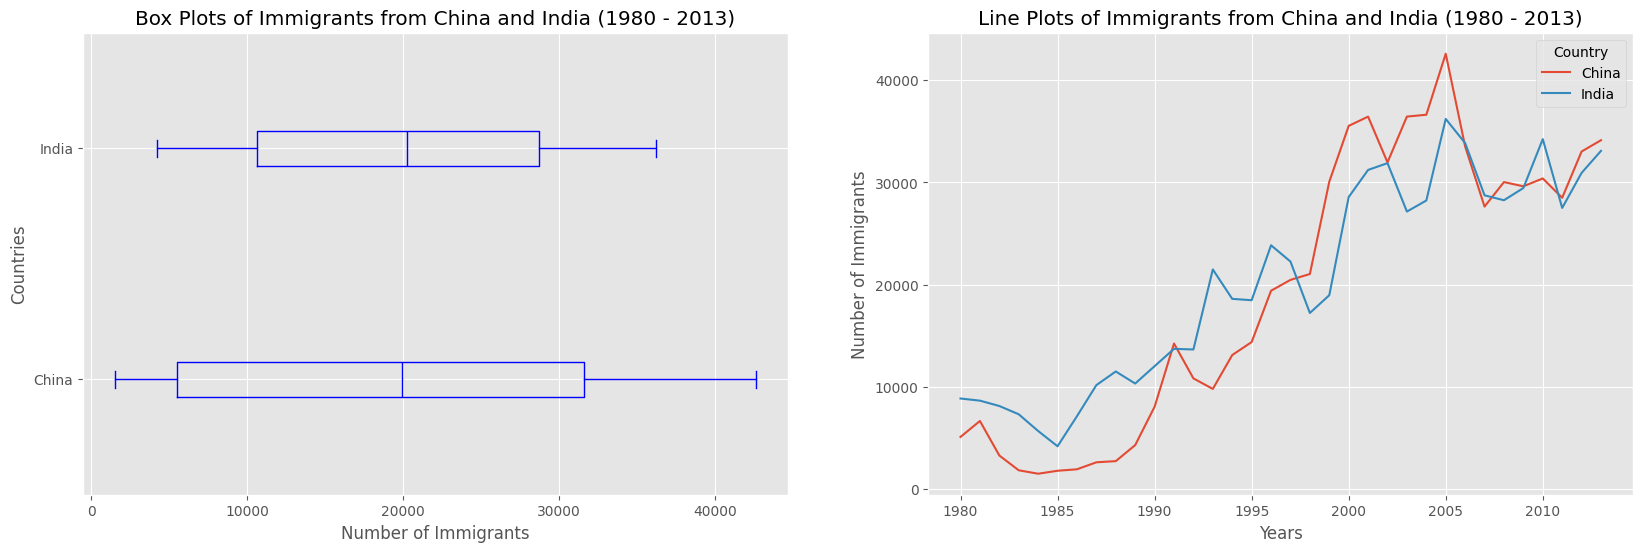

In [47]:
fig = plt.figure() # create figure

ax0 = fig.add_subplot(1, 2, 1) # add subplot 1 (1 row, 2 columns, first plot)
ax1 = fig.add_subplot(1, 2, 2) # add subplot 2 (1 row, 2 columns, second plot). See tip below**

# Subplot 1: Box plot
df_CI.plot(kind='box', color='blue', vert=False, figsize=(20, 6), ax=ax0) # add to subplot 1
ax0.set_title('Box Plots of Immigrants from China and India (1980 - 2013)')
ax0.set_xlabel('Number of Immigrants')
ax0.set_ylabel('Countries')

# Subplot 2: Line plot
df_CI.plot(kind='line', figsize=(20, 6), ax=ax1) # add to subplot 2
ax1.set_title ('Line Plots of Immigrants from China and India (1980 - 2013)')
ax1.set_ylabel('Number of Immigrants')
ax1.set_xlabel('Years')

plt.show()

**Mẹo về quy ước subplot**

Trong trường hợp `nrows`, `ncols` và `plot_number` đều nhỏ hơn 10, có một cách viết tắt cho phép dùng một số có 3 chữ số thay thế, trong đó chữ số hàng trăm là `nrows`, hàng chục là `ncols` và hàng đơn vị là `plot_number`. Ví dụ,
```python
   subplot(211) == subplot(2, 1, 1) 
```
tạo ra một subaxes trong figure biểu diễn biểu đồ ở trên cùng (tức là biểu đồ đầu tiên) trong một lưới khái niệm 2 dòng và 1 cột (thực tế không có lưới nào tồn tại, nhưng về mặt khái niệm thì subplot được trả về đã được định vị theo cách này).

Hãy thử một việc nâng cao hơn một chút. 

Trước đó chúng ta đã xác định 15 quốc gia hàng đầu dựa trên tổng lượng nhập cư từ 1980 - 2013.

**Câu hỏi:** Tạo một box plot để trực quan hóa phân phối của 15 quốc gia hàng đầu (dựa trên tổng lượng nhập cư) được nhóm theo các *thập niên* `1980s`, `1990s` và `2000s`.

Bước 1: Lấy bộ dữ liệu. Lấy 15 quốc gia hàng đầu dựa trên tổng dân số nhập cư (Total). Đặt tên dataframe là **df_top15**.

In [56]:
### type your answer here

df_top15 = df_can.sort_values('Total',ascending = False, axis = 0).head(15)
df_top15

,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,1986,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
Country,,,,,,,,,,,,,,,,,,,,,
India,Asia,Southern Asia,Developing regions,8880,8670,8147,7338,5704,4211,7150,...,36210,33848,28742,28261,29456,34235,27509,30933,33087,691904
China,Asia,Eastern Asia,Developing regions,5123,6682,3308,1863,1527,1816,1960,...,42584,33518,27642,30037,29622,30391,28502,33024,34129,659962
United Kingdom of Great Britain and Northern Ireland,Europe,Northern Europe,Developed regions,22045,24796,20620,10015,10170,9564,9470,...,7258,7140,8216,8979,8876,8724,6204,6195,5827,551500
Philippines,Asia,South-Eastern Asia,Developing regions,6051,5921,5249,4562,3801,3150,4166,...,18139,18400,19837,24887,28573,38617,36765,34315,29544,511391
Pakistan,Asia,Southern Asia,Developing regions,978,972,1201,900,668,514,691,...,14314,13127,10124,8994,7217,6811,7468,11227,12603,241600
United States of America,Northern America,Northern America,Developed regions,9378,10030,9074,7100,6661,6543,7074,...,8394,9613,9463,10190,8995,8142,7676,7891,8501,241122
Iran (Islamic Republic of),Asia,Southern Asia,Developing regions,1172,1429,1822,1592,1977,1648,1794,...,5837,7480,6974,6475,6580,7477,7479,7534,11291,175923
Sri Lanka,Asia,Southern Asia,Developing regions,185,371,290,197,1086,845,1838,...,4930,4714,4123,4756,4547,4422,3309,3338,2394,148358
Republic of Korea,Asia,Eastern Asia,Developing regions,1011,1456,1572,1081,847,962,1208,...,5832,6215,5920,7294,5874,5537,4588,5316,4509,142581


<details><summary>Nhấn vào đây để xem gợi ý về các hàm cần dùng</summary>

### 💡 Gợi ý

Bạn có thể cân nhắc các hàm sau:

- <code style="color:red">sort_values()</code> — sắp xếp giảm dần theo `Total` (chú ý `ascending` và `axis`).
- <code style="color:red">head()</code> — lấy 15 dòng đầu.

</details>

Bước 2: Tạo một dataframe mới chứa giá trị tổng hợp cho mỗi thập niên. Một cách để làm điều đó:
   1. Tạo một danh sách tất cả các năm trong các thập niên 80, 90 và 00.
   2. Cắt (slice) dataframe gốc df_can để tạo một series cho mỗi thập niên và cộng tổng qua tất cả các năm cho mỗi quốc gia.
   3. Gộp ba series thành một dataframe mới. Đặt tên dataframe là **new_df**.

In [ ]:
### type your answer here


<details><summary>Nhấn vào đây để xem gợi ý về các hàm cần dùng</summary>

### 💡 Gợi ý

Bạn có thể cân nhắc các hàm sau:

- <code style="color:red">list() / map() / range() / str()</code> — tạo danh sách các năm dạng **chuỗi** cho từng thập niên.
- <code style="color:red">loc[]</code> — chọn tất cả dòng (`:`) và các cột năm của thập niên.
- <code style="color:red">sum()</code> — cộng theo từng dòng (`axis=1`) để có tổng theo thập niên cho mỗi quốc gia.
- <code style="color:red">pd.DataFrame()</code> — gộp ba series thành một dataframe bằng dictionary.
- <code style="color:red">head()</code> — xem nhanh kết quả.

</details>

Hãy tìm hiểu thêm về các thống kê liên quan đến dataframe bằng phương thức `describe()`.

In [ ]:
### type your answer here


<details><summary>Nhấn vào đây để xem gợi ý về các hàm cần dùng</summary>

### 💡 Gợi ý

Bạn có thể cân nhắc các hàm sau:

- <code style="color:red">describe()</code> — gọi trên `new_df`.

</details>

Bước 3: Vẽ các box plot.

In [ ]:
### type your answer here




<details><summary>Nhấn vào đây để xem gợi ý về các hàm cần dùng</summary>

### 💡 Gợi ý

Bạn có thể cân nhắc các hàm sau:

- <code style="color:red">plot()</code> — `kind='box'` cùng `figsize`.
- <code style="color:red">plt.title()</code> — tiêu đề.
- <code style="color:red">plt.show()</code> — hiển thị biểu đồ.

</details>

Hãy lưu ý box plot khác với bảng tóm tắt đã tạo như thế nào. Box plot quét dữ liệu và xác định các outlier. Để trở thành một outlier, giá trị dữ liệu phải:<br>
* lớn hơn Q3 ít nhất 1.5 lần khoảng tứ phân vị (interquartile range - IQR), hoặc,
* nhỏ hơn Q1 ít nhất 1.5 lần IQR.

Hãy xem thập niên 2000s làm ví dụ: <br>
* Q1 (25%) = 36,101.5 <br>
* Q3 (75%) = 105,505.5 <br>
* IQR = Q3 - Q1 = 69,404 <br>

Theo định nghĩa outlier, bất kỳ giá trị nào lớn hơn Q3 một khoảng 1.5 lần IQR sẽ bị đánh dấu là outlier.

Outlier > 105,505.5 + (1.5 * 69,404) <br>
Outlier > 209,611.5

In [ ]:
# let's check how many entries fall above the outlier threshold 


<details><summary>Nhấn vào đây để xem gợi ý về các hàm cần dùng</summary>

### 💡 Gợi ý

Bạn có thể cân nhắc các hàm sau:

- <code style="color:red">reset_index()</code> — đưa tên quốc gia từ index thành một cột thường.
- <code style="color:red">Lọc theo điều kiện</code> — dùng biểu thức so sánh bên trong `[]` để chọn các dòng có giá trị lớn hơn ngưỡng outlier vừa tính.

</details>

Trung Quốc và Ấn Độ đều được coi là outlier vì dân số của họ trong thập niên này vượt quá 209,611.5. 

Box plot là một công cụ trực quan hóa nâng cao, và có nhiều tùy chọn và tùy chỉnh vượt quá phạm vi của bài thực hành này. Vui lòng tham khảo [tài liệu Matplotlib](http://matplotlib.org/api/pyplot_api.html#matplotlib.pyplot.boxplot) về box plot để biết thêm thông tin.

# Biểu đồ phân tán (Scatter Plots) <a id="10"></a>

`Scatter plot` (2D) là một phương pháp hữu ích để so sánh các biến với nhau. Các biểu đồ `Scatter` trông giống `line plots` ở chỗ cả hai đều ánh xạ biến độc lập và biến phụ thuộc trên một đồ thị 2D. Trong khi các điểm dữ liệu được nối với nhau bằng một đường trong line plot, chúng không được nối trong scatter plot. Dữ liệu trong scatter plot được coi là biểu thị một xu hướng. Với phân tích sâu hơn bằng các công cụ như hồi quy (regression), chúng ta có thể tính toán mối quan hệ này về mặt toán học và dùng nó để dự đoán các xu hướng nằm ngoài bộ dữ liệu.

Hãy bắt đầu bằng việc khám phá điều sau:

Sử dụng `scatter plot`, hãy trực quan hóa xu hướng tổng lượng nhập cư vào Canada (gộp tất cả các quốc gia) trong các năm 1980 - 2013.

Bước 1: Lấy bộ dữ liệu. Vì chúng ta dự định dùng mối quan hệ giữa `years` và `total population`, chúng ta sẽ chuyển `years` sang kiểu `int`.

In [ ]:
# we can use the sum() method to get the total population per year
df_tot = pd.DataFrame(df_can[years].sum(axis=0))

# change the years to type int (useful for regression later on)
df_tot.index = map(int, df_tot.index)

# reset the index to put in back in as a column in the df_tot dataframe
df_tot.reset_index(inplace = True)

# rename columns
df_tot.columns = ['year', 'total']

# view the final dataframe
df_tot.head()

Bước 2: Vẽ dữ liệu. Trong `Matplotlib`, chúng ta có thể tạo biểu đồ `scatter` bằng cách truyền `kind='scatter'` làm đối số của plot. Chúng ta cũng cần truyền các từ khóa `x` và `y` để chỉ định các cột đặt trên trục x và trục y.

In [ ]:
df_tot.plot(kind='scatter', x='year', y='total', figsize=(10, 6), color='darkblue')

plt.title('Total Immigration to Canada from 1980 - 2013')
plt.xlabel('Year')
plt.ylabel('Number of Immigrants')

plt.show()

Hãy lưu ý rằng scatter plot không nối các điểm dữ liệu với nhau. Chúng ta có thể quan sát rõ xu hướng đi lên trong dữ liệu: theo thời gian, tổng số người nhập cư tăng lên. Chúng ta có thể phân tích xu hướng đi lên này về mặt toán học bằng đường hồi quy (regression line - đường phù hợp nhất, line of best fit).

Vì vậy, hãy thử vẽ một đường thẳng phù hợp nhất (line of best fit) và dùng nó để dự đoán số người nhập cư vào năm 2015.

Bước 1: Lấy phương trình của đường phù hợp nhất. Chúng ta sẽ dùng phương thức `polyfit()` của **Numpy** bằng cách truyền vào:
- `x`: tọa độ x của dữ liệu. 
- `y`: tọa độ y của dữ liệu. 
- `deg`: Bậc của đa thức khớp (fitting polynomial). 1 = tuyến tính (linear), 2 = bậc hai (quadratic), v.v.

In [ ]:
x = df_tot['year']      # year on x-axis
y = df_tot['total']     # total on y-axis
fit = np.polyfit(x, y, deg=1)

fit

Kết quả đầu ra là một mảng chứa các hệ số của đa thức, với lũy thừa cao nhất đứng đầu. Vì chúng ta đang vẽ hồi quy tuyến tính `y= a * x + b`, đầu ra của chúng ta có 2 phần tử `[5.56709228e+03, -1.09261952e+07]` với hệ số góc (slope) ở vị trí 0 và hệ số chặn (intercept) ở vị trí 1.

Bước 2: Vẽ đường hồi quy lên `scatter plot`.

In [ ]:
df_tot.plot(kind='scatter', x='year', y='total', figsize=(10, 6), color='darkblue')

plt.title('Total Immigration to Canada from 1980 - 2013')
plt.xlabel('Year')
plt.ylabel('Number of Immigrants')

# plot line of best fit
plt.plot(x, fit[0] * x + fit[1], color='red') # recall that x is the Years
plt.annotate('y={0:.0f} x + {1:.0f}'.format(fit[0], fit[1]), xy=(2000, 150000))

plt.show()

# print out the line of best fit
'No. Immigrants = {0:.0f} * Year + {1:.0f}'.format(fit[0], fit[1]) 

Sử dụng phương trình của đường phù hợp nhất, chúng ta có thể ước tính số người nhập cư vào năm 2015:
```python
No. Immigrants = 5567 * Year - 10926195
No. Immigrants = 5567 * 2015 - 10926195
No. Immigrants = 291,310
```
Khi so sánh với số liệu thực tế từ [Báo cáo thường niên 2016](http://www.cic.gc.ca/english/resources/publications/annual-report-2016/index.asp) của Bộ Di trú và Quốc tịch Canada (Citizenship and Immigration Canada - CIC), chúng ta thấy Canada đã tiếp nhận 271,845 người nhập cư vào năm 2015. Giá trị ước tính 291,310 của chúng ta nằm trong khoảng 7% so với con số thực tế, khá tốt khi xét rằng dữ liệu gốc của chúng ta đến từ Liên Hợp Quốc (và có thể khác đôi chút so với dữ liệu của CIC).

Lưu ý thêm, chúng ta có thể quan sát thấy lượng nhập cư sụt giảm vào khoảng năm 1993 - 1997. Phân tích sâu hơn về chủ đề này cho thấy vào năm 1993, Canada đã ban hành Dự luật C-86 (Bill C-86), đưa ra các sửa đổi đối với hệ thống xác định tư cách người tị nạn, chủ yếu mang tính hạn chế. Các sửa đổi tiếp theo đối với Quy định Nhập cư đã hủy bỏ yêu cầu bảo lãnh đối với "người thân được hỗ trợ" ("assisted relatives") và giảm điểm dành cho họ, khiến các thành viên gia đình (ngoài gia đình hạt nhân) khó nhập cư vào Canada hơn. Những biện pháp hạn chế này đã tác động trực tiếp đến số liệu nhập cư trong vài năm tiếp theo.

**Câu hỏi**: Tạo một scatter plot về tổng lượng nhập cư từ Đan Mạch (Denmark), Na Uy (Norway) và Thụy Điển (Sweden) vào Canada từ năm 1980 đến 2013?

**Bước 1**: Lấy dữ liệu:
   1. Tạo một dataframe chỉ chứa các con số liên quan đến Denmark, Norway và Sweden. Đặt tên là **df_countries**.
   2. Cộng tổng số người nhập cư của cả ba quốc gia cho mỗi năm và chuyển kết quả thành một dataframe. Đặt tên dataframe mới này là **df_total**.
   3. Reset index tại chỗ (in place).
   4. Đổi tên các cột thành **year** và **total**.
   5. Hiển thị dataframe kết quả.

In [ ]:
### type your answer here





<details><summary>Nhấn vào đây để xem gợi ý về các hàm cần dùng</summary>

### 💡 Gợi ý

Bạn có thể cân nhắc các hàm sau:

- <code style="color:red">loc[]</code> — chọn 3 quốc gia và các cột năm.
- <code style="color:red">transpose()</code> — hoán đổi dòng/cột.
- <code style="color:red">sum()</code> — cộng tổng theo từng dòng (`axis=1`).
- <code style="color:red">pd.DataFrame()</code> — chuyển series kết quả thành dataframe.
- <code style="color:red">reset_index()</code> — dùng `inplace=True`.
- <code style="color:red">columns</code> — gán danh sách tên cột mới cho dataframe.
- <code style="color:red">astype()</code> — đổi cột `year` sang số nguyên.
- <code style="color:red">head()</code> — xem nhanh kết quả.

</details>

**Bước 2**: Tạo scatter plot bằng cách vẽ total theo year trong **df_total**.

In [ ]:
### type your answer here





<details><summary>Nhấn vào đây để xem gợi ý về các hàm cần dùng</summary>

### 💡 Gợi ý

Bạn có thể cân nhắc các hàm sau:

- <code style="color:red">plot()</code> — `kind='scatter'` cùng `x`, `y`, `figsize`, `color`.
- <code style="color:red">plt.title()</code> — đặt tiêu đề cho biểu đồ.
- <code style="color:red">plt.xlabel() / plt.ylabel()</code> — gán nhãn cho trục x và trục y.
- <code style="color:red">plt.show()</code> — hiển thị biểu đồ.

</details>

# Biểu đồ bong bóng (Bubble Plots) <a id="12"></a>

`Bubble plot` là một biến thể của `scatter plot` hiển thị ba chiều dữ liệu (x, y, z). Các điểm dữ liệu được thay bằng các bong bóng, và kích thước của bong bóng được xác định bởi biến thứ ba `z`, còn gọi là trọng số (weight). Trong `maplotlib`, chúng ta có thể truyền một mảng hoặc một giá trị vô hướng (scalar) vào tham số `s` của `plot()`, chứa trọng số của từng điểm.

**Hãy bắt đầu bằng việc phân tích tác động của cuộc Đại suy thoái của Argentina**.

Argentina đã trải qua một cuộc đại suy thoái từ năm 1998 đến 2002, gây ra tình trạng thất nghiệp lan rộng, bạo loạn, sự sụp đổ của chính phủ và việc quốc gia này vỡ nợ nước ngoài. Xét về thu nhập, hơn 50% người dân Argentina nghèo, và bảy trên mười trẻ em Argentina nghèo vào thời điểm khủng hoảng sâu nhất năm 2002.

Hãy phân tích tác động của cuộc khủng hoảng này, và so sánh lượng nhập cư của Argentina với nước láng giềng Brazil. Chúng ta sẽ làm điều đó bằng `bubble plot` về lượng nhập cư từ Brazil và Argentina trong các năm 1980 - 2013. Chúng ta sẽ đặt trọng số cho bong bóng là giá trị *chuẩn hóa (normalized)* của dân số mỗi năm.

**Bước 1**: Lấy dữ liệu của Brazil và Argentina. Giống như ví dụ trước, chúng ta sẽ chuyển `Years` sang kiểu int và đưa nó vào dataframe.

In [ ]:
# transposed dataframe
df_can_t = df_can[years].transpose()

# cast the Years (the index) to type int
df_can_t.index = map(int, df_can_t.index)

# let's label the index. This will automatically be the column name when we reset the index
df_can_t.index.name = 'Year'

# reset index to bring the Year in as a column
df_can_t.reset_index(inplace=True)

# view the changes
df_can_t.head()

**Bước 2**: Tạo các trọng số đã chuẩn hóa.

Có nhiều phương pháp chuẩn hóa trong thống kê, mỗi phương pháp có công dụng riêng. Trong trường hợp này, chúng ta sẽ dùng [feature scaling](https://en.wikipedia.org/wiki/Feature_scaling) để đưa tất cả các giá trị về khoảng [0, 1]. Công thức chung là:

<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/Module%203/images/Mod3Fig3FeatureScaling.png" align="center">

trong đó $X$ là giá trị gốc, $X'$ là giá trị chuẩn hóa tương ứng. Công thức đặt giá trị lớn nhất trong bộ dữ liệu bằng 1 và giá trị nhỏ nhất bằng 0. Các điểm dữ liệu còn lại được co giãn về giá trị trong khoảng 0-1 tương ứng.

In [ ]:
# normalize Brazil data
norm_brazil = (df_can_t['Brazil'] - df_can_t['Brazil'].min()) / (df_can_t['Brazil'].max() - df_can_t['Brazil'].min())

# normalize Argentina data
norm_argentina = (df_can_t['Argentina'] - df_can_t['Argentina'].min()) / (df_can_t['Argentina'].max() - df_can_t['Argentina'].min())

**Bước 3**: Vẽ dữ liệu.
- Để vẽ hai scatter plot khác nhau trong một biểu đồ, chúng ta có thể đưa axes của biểu đồ này vào biểu đồ kia bằng cách truyền nó qua tham số `ax`. 
- Chúng ta cũng sẽ truyền các trọng số bằng tham số `s`. Vì các trọng số đã chuẩn hóa nằm trong khoảng 0-1, chúng sẽ không hiển thị được trên biểu đồ. Do đó, chúng ta sẽ:
    - nhân trọng số với 2000 để phóng to trên đồ thị, và,
    - cộng thêm 10 để bù cho giá trị nhỏ nhất (có trọng số bằng 0 và do đó khi nhân với $\times 2000$ vẫn bằng 0).

In [ ]:
# Brazil
ax0 = df_can_t.plot(kind='scatter',
                    x='Year',
                    y='Brazil',
                    figsize=(14, 8),
                    alpha=0.5,  # transparency
                    color='green',
                    s=norm_brazil * 2000 + 10,  # pass in weights 
                    xlim=(1975, 2015)
                    )

# Argentina
ax1 = df_can_t.plot(kind='scatter',
                    x='Year',
                    y='Argentina',
                    alpha=0.5,
                    color="blue",
                    s=norm_argentina * 2000 + 10,
                    ax=ax0
                    )

ax0.set_ylabel('Number of Immigrants')
ax0.set_title('Immigration from Brazil and Argentina from 1980 to 2013')
ax0.legend(['Brazil', 'Argentina'], loc='upper left', fontsize='x-large')

Kích thước của bong bóng tương ứng với độ lớn của dân số nhập cư trong năm đó, so với dữ liệu 1980 - 2013. Bong bóng càng lớn thì năm đó càng có nhiều người nhập cư.

Từ biểu đồ trên, chúng ta có thể thấy lượng nhập cư từ Argentina tăng tương ứng trong giai đoạn đại suy thoái 1998 - 2002. Chúng ta cũng có thể quan sát thấy một mức tăng vọt tương tự vào khoảng năm 1985 đến 1993. Thực tế, Argentina đã trải qua một cuộc đại suy thoái từ năm 1974 đến 1990, ngay trước khi cuộc đại suy thoái 1998 - 2002 bắt đầu.

Tương tự, Brazil đã chịu *Hiệu ứng Samba (Samba Effect)* khi đồng real của Brazil (tiền tệ) mất giá gần 35% vào năm 1999. Đã có nỗi lo về một cuộc khủng hoảng tài chính Nam Mỹ vì nhiều quốc gia Nam Mỹ phụ thuộc nhiều vào xuất khẩu công nghiệp từ Brazil. Chính phủ Brazil sau đó đã áp dụng chương trình thắt lưng buộc bụng, và nền kinh tế dần phục hồi qua các năm, đạt đỉnh với một đợt tăng vọt vào năm 2010. Dữ liệu nhập cư phản ánh các sự kiện này.

**Câu hỏi**: Trước đó trong bài thực hành này, chúng ta đã tạo các box plot để so sánh lượng nhập cư từ Trung Quốc và Ấn Độ vào Canada. Hãy tạo các bubble plot về lượng nhập cư từ Trung Quốc và Ấn Độ để trực quan hóa mọi khác biệt theo thời gian từ 1980 đến 2013. Bạn có thể dùng **df_can_t** mà chúng ta đã định nghĩa và sử dụng trong ví dụ trước.

Bước 1: Chuẩn hóa dữ liệu của Trung Quốc và Ấn Độ.

In [ ]:
### type your answer here

# normalized Chinese data
# norm_china = ...
# normalized Indian data
# norm_india = ...



<details><summary>Nhấn vào đây để xem gợi ý về các hàm cần dùng</summary>

### 💡 Gợi ý

Bạn có thể cân nhắc các hàm sau:

- <code style="color:red">min() / max()</code> — lấy giá trị nhỏ nhất/lớn nhất của từng cột.
- <code style="color:red">Công thức chuẩn hóa</code> — (x − min) / (max − min) cho cột China và cột India.

</details>

Bước 2: Tạo các bubble plot.

In [ ]:
### type your answer here





<details><summary>Nhấn vào đây để xem gợi ý về các hàm cần dùng</summary>

### 💡 Gợi ý

Bạn có thể cân nhắc các hàm sau:

- <code style="color:red">plot()</code> — `kind='scatter'` với `x`, `y`, `alpha`, `color`, `xlim`, và `s` để đặt kích thước bong bóng theo trọng số đã chuẩn hóa.
- <code style="color:red">plot(..., ax=...)</code> — truyền `Axes` của biểu đồ đầu vào biểu đồ thứ hai để vẽ chồng lên nhau.
- <code style="color:red">ax.set_ylabel() / ax.set_title()</code> — đặt nhãn và tiêu đề.
- <code style="color:red">ax.legend()</code> — thêm chú giải cho 2 quốc gia.

> **Mẹo:** Nhân trọng số với một số đủ lớn (và cộng thêm một hằng số nhỏ) để các bong bóng nhìn thấy được.

</details>

### Cảm ơn bạn đã hoàn thành bài thực hành này!


## Tác giả

<a href="https://www.linkedin.com/in/aklson/" target="_blank">Alex Aklson</a>


### Những người đóng góp khác
[Jay Rajasekharan](https://www.linkedin.com/in/jayrajasekharan),
[Ehsan M. Kermani](https://www.linkedin.com/in/ehsanmkermani),
[Slobodan Markovic](https://www.linkedin.com/in/slobodan-markovic),
[Weiqing Wang](https://www.linkedin.com/in/weiqing-wang-641640133).


## Nhật ký thay đổi


|  Ngày (YYYY-MM-DD) |  Phiên bản | Người thay đổi  |  Mô tả thay đổi |
|---|---|---|---|
| 2021-05-29 | 2.6 | Weiqing Wang | Sửa lỗi chính tả và code smell. |
| 2021-01-20  | 2.5 | LakshmiHolla  | Thay đổi phần markdown của mục lục (TOC)|
| 2021-01-05  | 2.4  | LakshmiHolla  |  Thay đổi markdown cho outlier |
| 2020-11-12  | 2.3  | LakshmiHolla  |  Thêm code ví dụ cho outlier |
| 2020-11-03  | 2.2  | LakshmiHolla  |  Thay đổi URL của tệp excel |
| 2020-09-29  | 2.1  | LakshmiHolla  |  Sửa nhãn của boxplot |
| 2020-08-27  | 2.0  | Lavanya  |  Chuyển bài thực hành vào repo khóa học trên GitLab |



## <h3 align="center"> © IBM Corporation 2020. Bảo lưu mọi quyền. <h3/>